# UTS Deep Learning - Task 1: Multimodal Defect Classification
**Objektif**: Mengklasifikasikan cacat produk manufaktur ke dalam 7 kelas persis: `normal`, `gores`, `noda`, `retak`, `gelembung`, `las_dingin`, `kontaminasi`  
**Metrik Penilaian Utama**: Macro-F1 Score atas 7 kelas  
**Modalitas Input**:  
1. **Kamera Citra**: Permukaan komponen 64x64 piksel monokrom (uint8)  
2. **Sensor Tekan**: Sinyal 3 kanal sepanjang 128 timestep (Kanal 0: Suhu °C, Kanal 1: Getaran relatif, Kanal 2: Arus A)



In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import Image, display

# Dynamic Root Discovery (Bekerja secara deterministik dari direktori mana pun)
current_dir = os.path.abspath('')
project_root = current_dir
for _ in range(6):
    if os.path.exists(os.path.join(project_root, 'data', 'cache')) or os.path.exists(os.path.join(project_root, 'data')):
        break
    parent = os.path.dirname(project_root)
    if parent == project_root:
        break
    project_root = parent
else:
    if os.path.exists('C:/DL_Classification/data/cache'):
        project_root = 'C:/DL_Classification'

cache_dir = os.path.join(project_root, 'data', 'cache')
artifacts_dir = os.path.join(project_root, 'artifacts', 'task1')
if not os.path.exists(artifacts_dir) and os.path.exists(os.path.join(project_root, 'artifacts')):
    artifacts_dir = os.path.join(project_root, 'artifacts')
if not os.path.exists(artifacts_dir) and os.path.exists('C:/DL_Classification/artifacts/task1'):
    artifacts_dir = 'C:/DL_Classification/artifacts/task1'

src_dir = os.path.join(project_root, 'kode', 'task1_klasifikasi')
if not os.path.exists(src_dir):
    src_dir = os.path.join(project_root, 'kode', 'Task1_Klasifikasi')

if os.path.exists(src_dir) and src_dir not in sys.path:
    sys.path.insert(0, src_dir)

try:
    from src.utils import seed_everything
    seed_everything(42)
except Exception:
    pass

print('Project Root  :', project_root)
print('Cache Dir     :', cache_dir)
print('Artifacts Dir :', artifacts_dir)
print('PyTorch Versi :', torch.__version__)
print('CUDA Status   :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU Device    :', torch.cuda.get_device_name(0))


Project Root  : c:\DL_Classification
Cache Dir     : c:\DL_Classification\data\cache
Artifacts Dir : c:\DL_Classification\artifacts\task1
PyTorch Versi : 2.6.0+cu124
CUDA Status   : True
GPU Device    : NVIDIA GeForce GTX 1050 Ti


## 1. Pemuatan Metadata & Verifikasi Data
Data mentah di-*cache* ke format NumPy dan Parquet di `data/cache/` agar training efisien dan terhindar dari I/O bottleneck.

In [2]:
# 1. Import library penting (memastikan cell dapat dijalankan langsung secara mandiri)
import os
import json
import pandas as pd

# 2. Pastikan path cache tersedia (self-contained fallback jika cell 1 belum dijalankan)
if 'cache_dir' not in globals() or not os.path.exists(cache_dir):
    c_cand = os.path.abspath('')
    for _ in range(6):
        if os.path.exists(os.path.join(c_cand, 'data', 'cache')):
            cache_dir = os.path.join(c_cand, 'data', 'cache')
            break
        c_cand = os.path.dirname(c_cand)
    else:
        if os.path.exists('C:/DL_Classification/data/cache'):
            cache_dir = 'C:/DL_Classification/data/cache'
        else:
            raise FileNotFoundError('Folder data/cache tidak ditemukan. Pastikan data_uts_dl.zip sudah diekstrak!')

# 3. Pemuatan Pemetaan Kelas
mapping_file = os.path.join(cache_dir, 'class_mapping.json')
if os.path.exists(mapping_file):
    with open(mapping_file) as f:
        mapping = json.load(f)
    class_names = mapping['class_names']
else:
    class_names = ['normal', 'gores', 'noda', 'retak', 'gelembung', 'las_dingin', 'kontaminasi']
print('7 Kelas Target Persis:', class_names)

# 4. Pemuatan Metadata Latih & Uji (Dual Support: Parquet dengan otomatis Fallback ke CSV)
train_pq = os.path.join(cache_dir, 'train_meta.parquet')
test_pq = os.path.join(cache_dir, 'test_meta.parquet')
train_csv = os.path.join(cache_dir, 'train_meta.csv')
test_csv = os.path.join(cache_dir, 'test_meta.csv')

try:
    train_meta = pd.read_parquet(train_pq)
    test_meta = pd.read_parquet(test_pq)
except Exception:
    train_meta = pd.read_csv(train_csv)
    test_meta = pd.read_csv(test_csv)

print(f'Data Latih: {len(train_meta):,} sampel | Data Uji: {len(test_meta):,} sampel')
train_meta.head()


7 Kelas Target Persis: ['normal', 'gores', 'noda', 'retak', 'gelembung', 'las_dingin', 'kontaminasi']
Data Latih: 48,000 sampel | Data Uji: 16,000 sampel


,indeks,id_unit,lini,shift,id_mesin,batch_material,kelas
0,0,U384670,A,pagi,M05,B135,gores
1,1,U487023,A,malam,M04,B146,gores
2,2,U327240,B,pagi,M09,B003,normal
3,3,U696502,A,siang,M06,B085,noda
4,4,U272751,B,siang,M08,B106,normal


## 2. Eksplorasi Data (Task a: EDA)
### a. Visualisasi Contoh Tiap Kelas pada Kedua Modalitas (Grid Gambar + Sinyal Sensor)

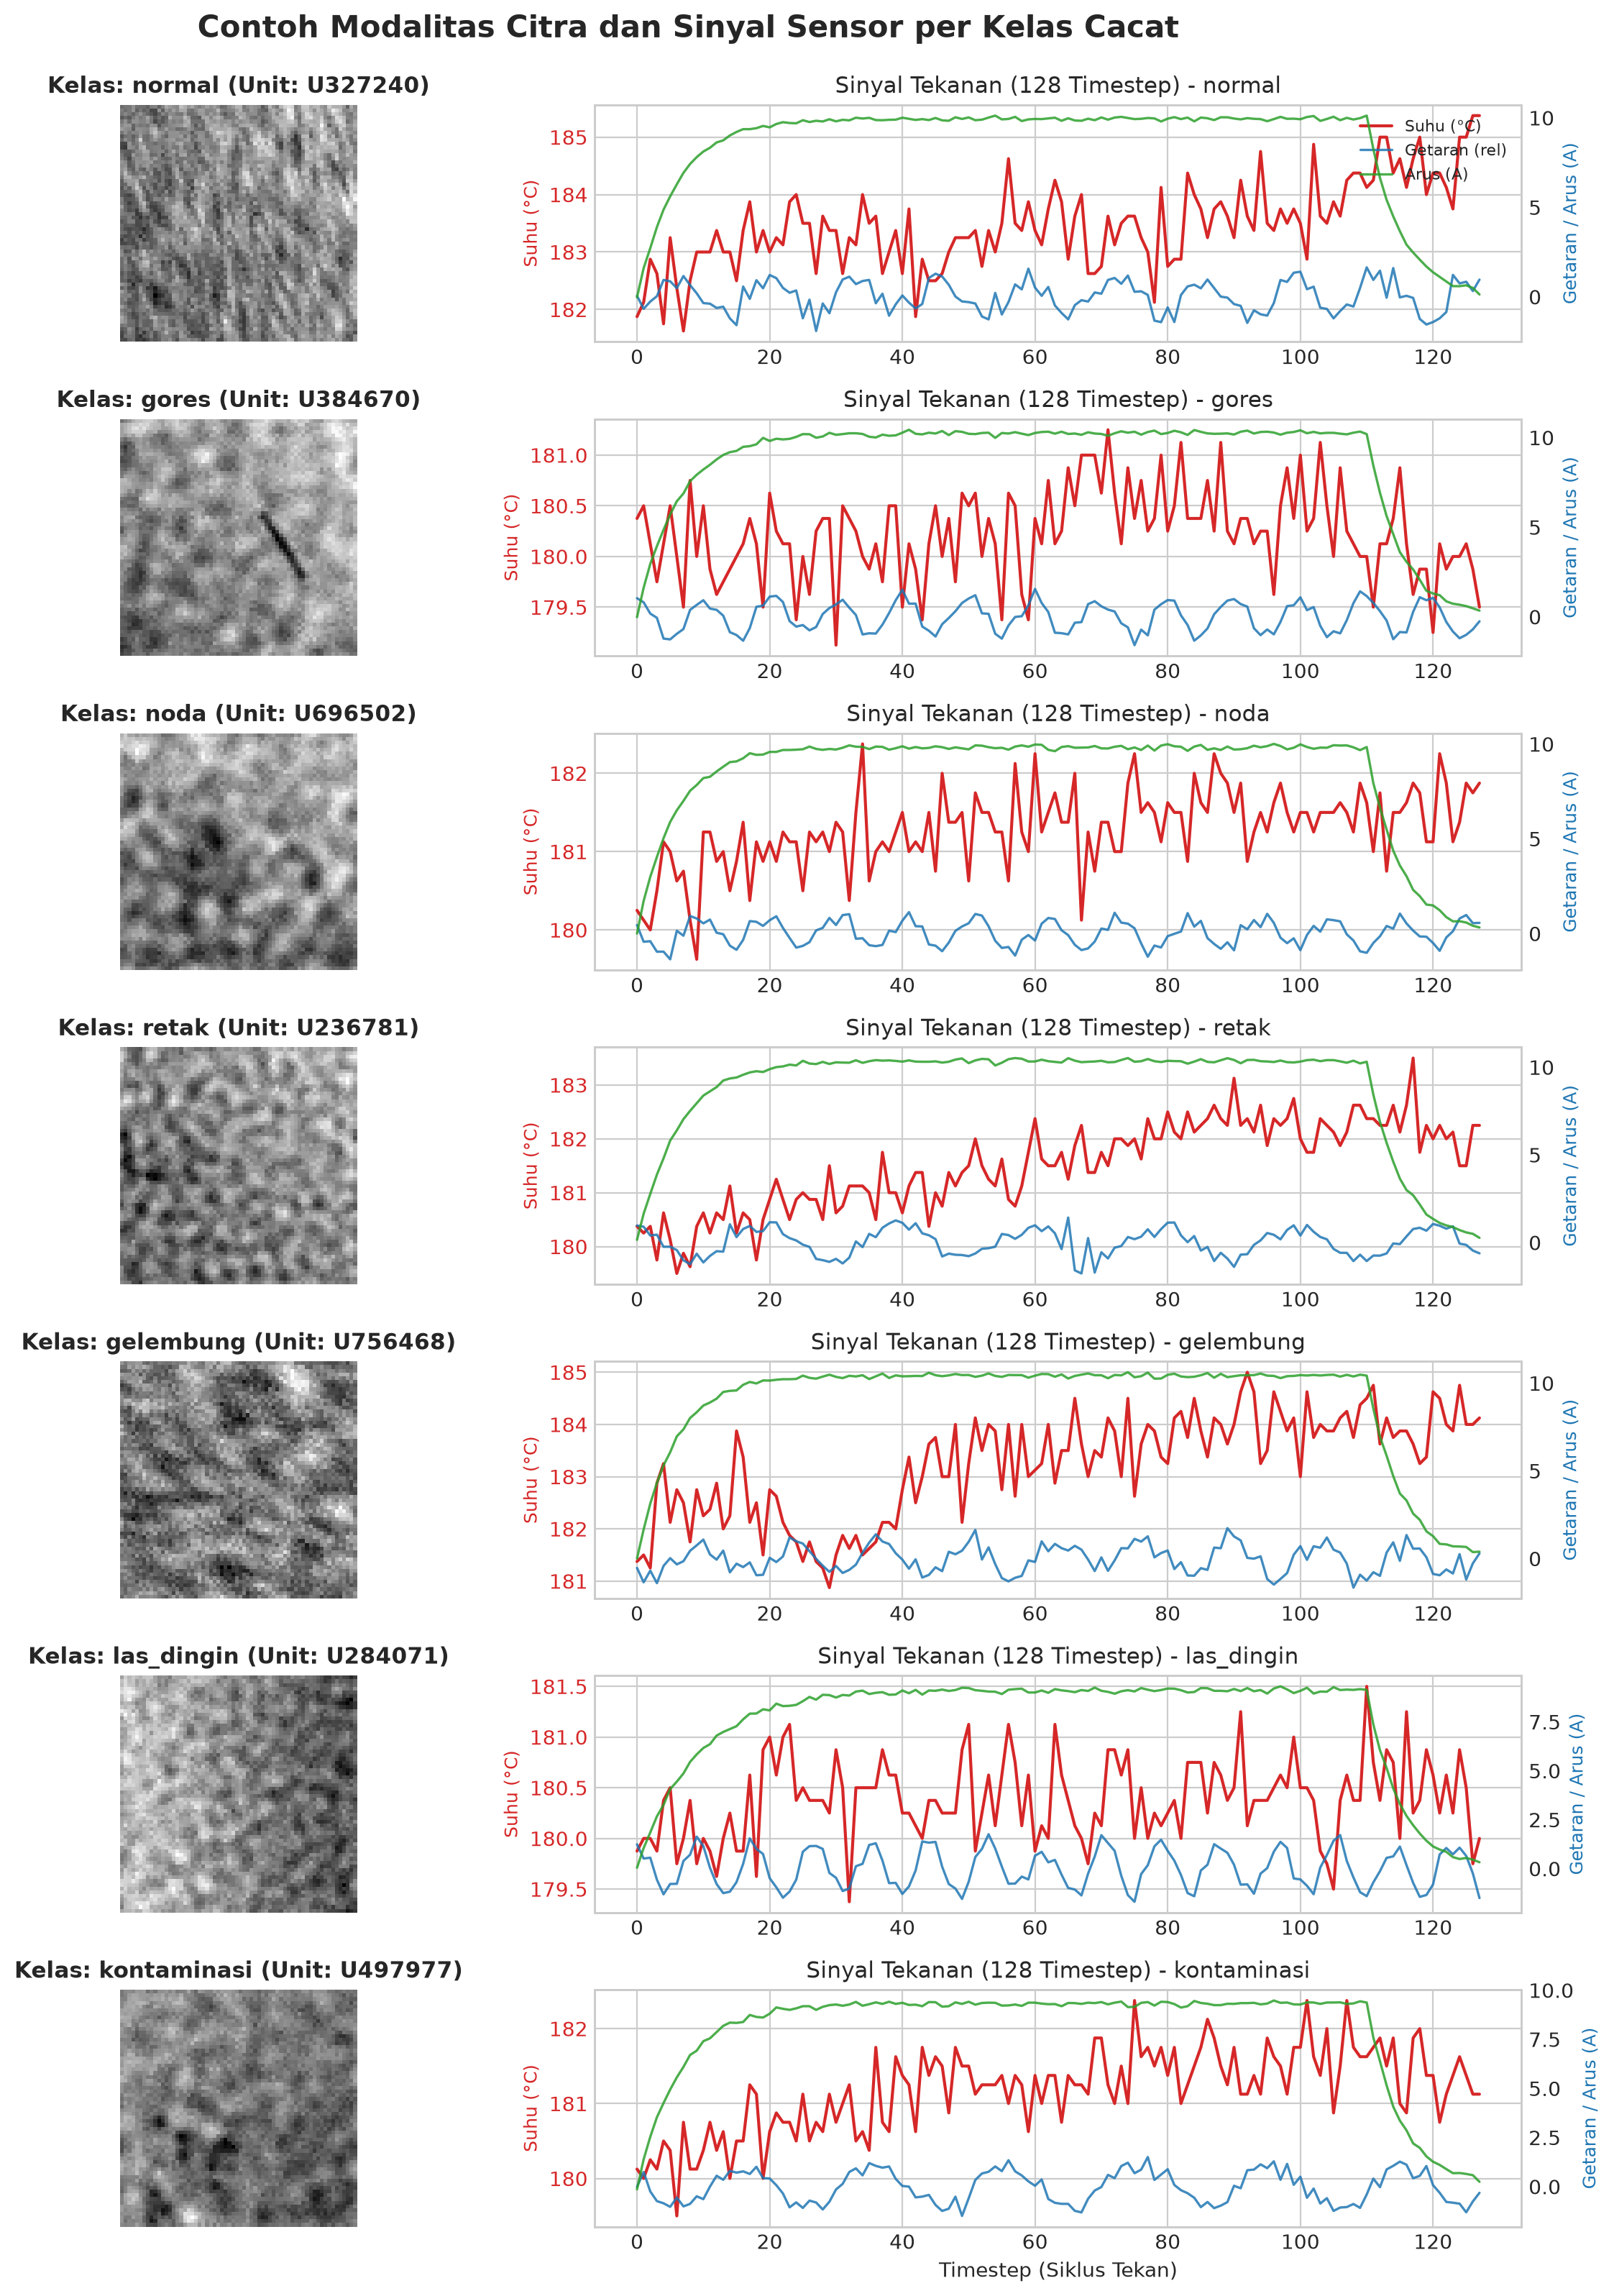

In [3]:
fig_a1 = os.path.join(artifacts_dir, 'fig_a1_multimodal_examples.png')
if os.path.exists(fig_a1):
    display(Image(filename=fig_a1))
else:
    print("Figur A1 belum digenerasi.")

### b. Distribusi Kelas & Severe Domain Shift Lini Produksi
Perhatikan bahwa kelas `normal` mendominasi hampir 50% populasi latih. Selain itu, terdapat **domain shift ekstrem**: Lini A mendominasi 75% di data latih, sedangkan pada data uji berbalik menjadi 60% didominasi Lini B.

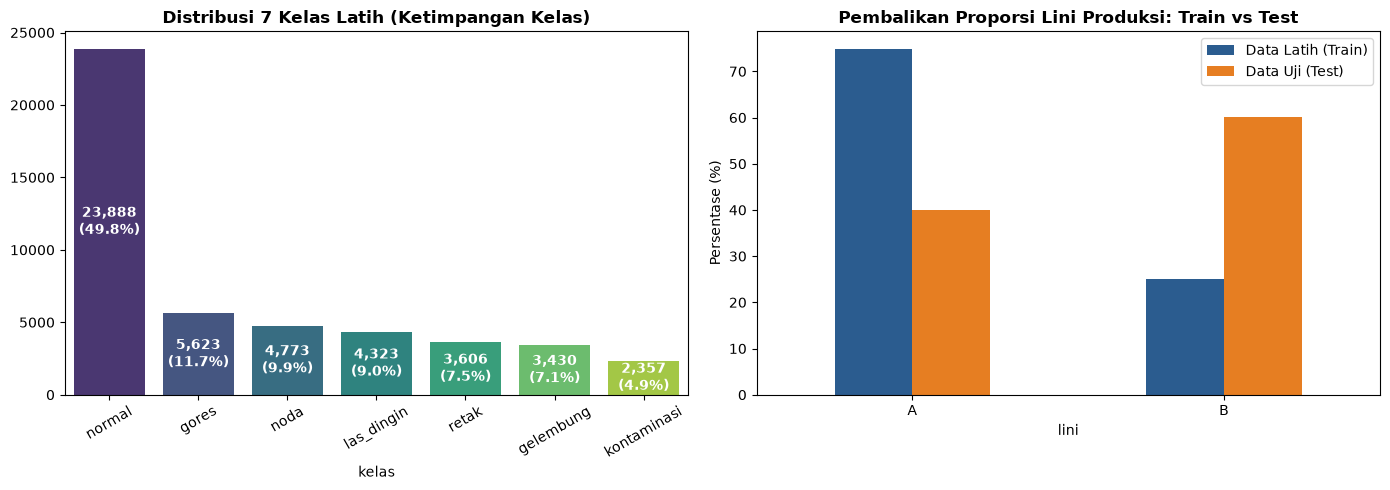

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Distribusi Kelas
counts = train_meta['kelas'].value_counts()
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False, ax=axes[0], palette='viridis')
axes[0].set_title("Distribusi 7 Kelas Latih (Ketimpangan Kelas)", fontsize=12, fontweight='bold')
axes[0].set_xticks(range(len(counts)))
axes[0].set_xticklabels(counts.index, rotation=30)
for p in axes[0].patches:
    pct = p.get_height() / len(train_meta) * 100
    axes[0].annotate(f"{int(p.get_height()):,}\n({pct:.1f}%)",
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

# Plot 2: Pergeseran Domain Lini Produksi (Train vs Test)
drift_df = pd.DataFrame({
    'Data Latih (Train)': train_meta['lini'].value_counts(normalize=True) * 100,
    'Data Uji (Test)': test_meta['lini'].value_counts(normalize=True) * 100
})
drift_df.plot(kind='bar', ax=axes[1], color=['#2b5c8f', '#e67e22'])
axes[1].set_title("Pembalikan Proporsi Lini Produksi: Train vs Test", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Persentase (%)")
axes[1].set_xticks(range(len(drift_df)))
axes[1].set_xticklabels(drift_df.index, rotation=0)
plt.tight_layout()
plt.show()

### c. Analisis Sensor Hilang (Missing Rate ~5% MCAR)

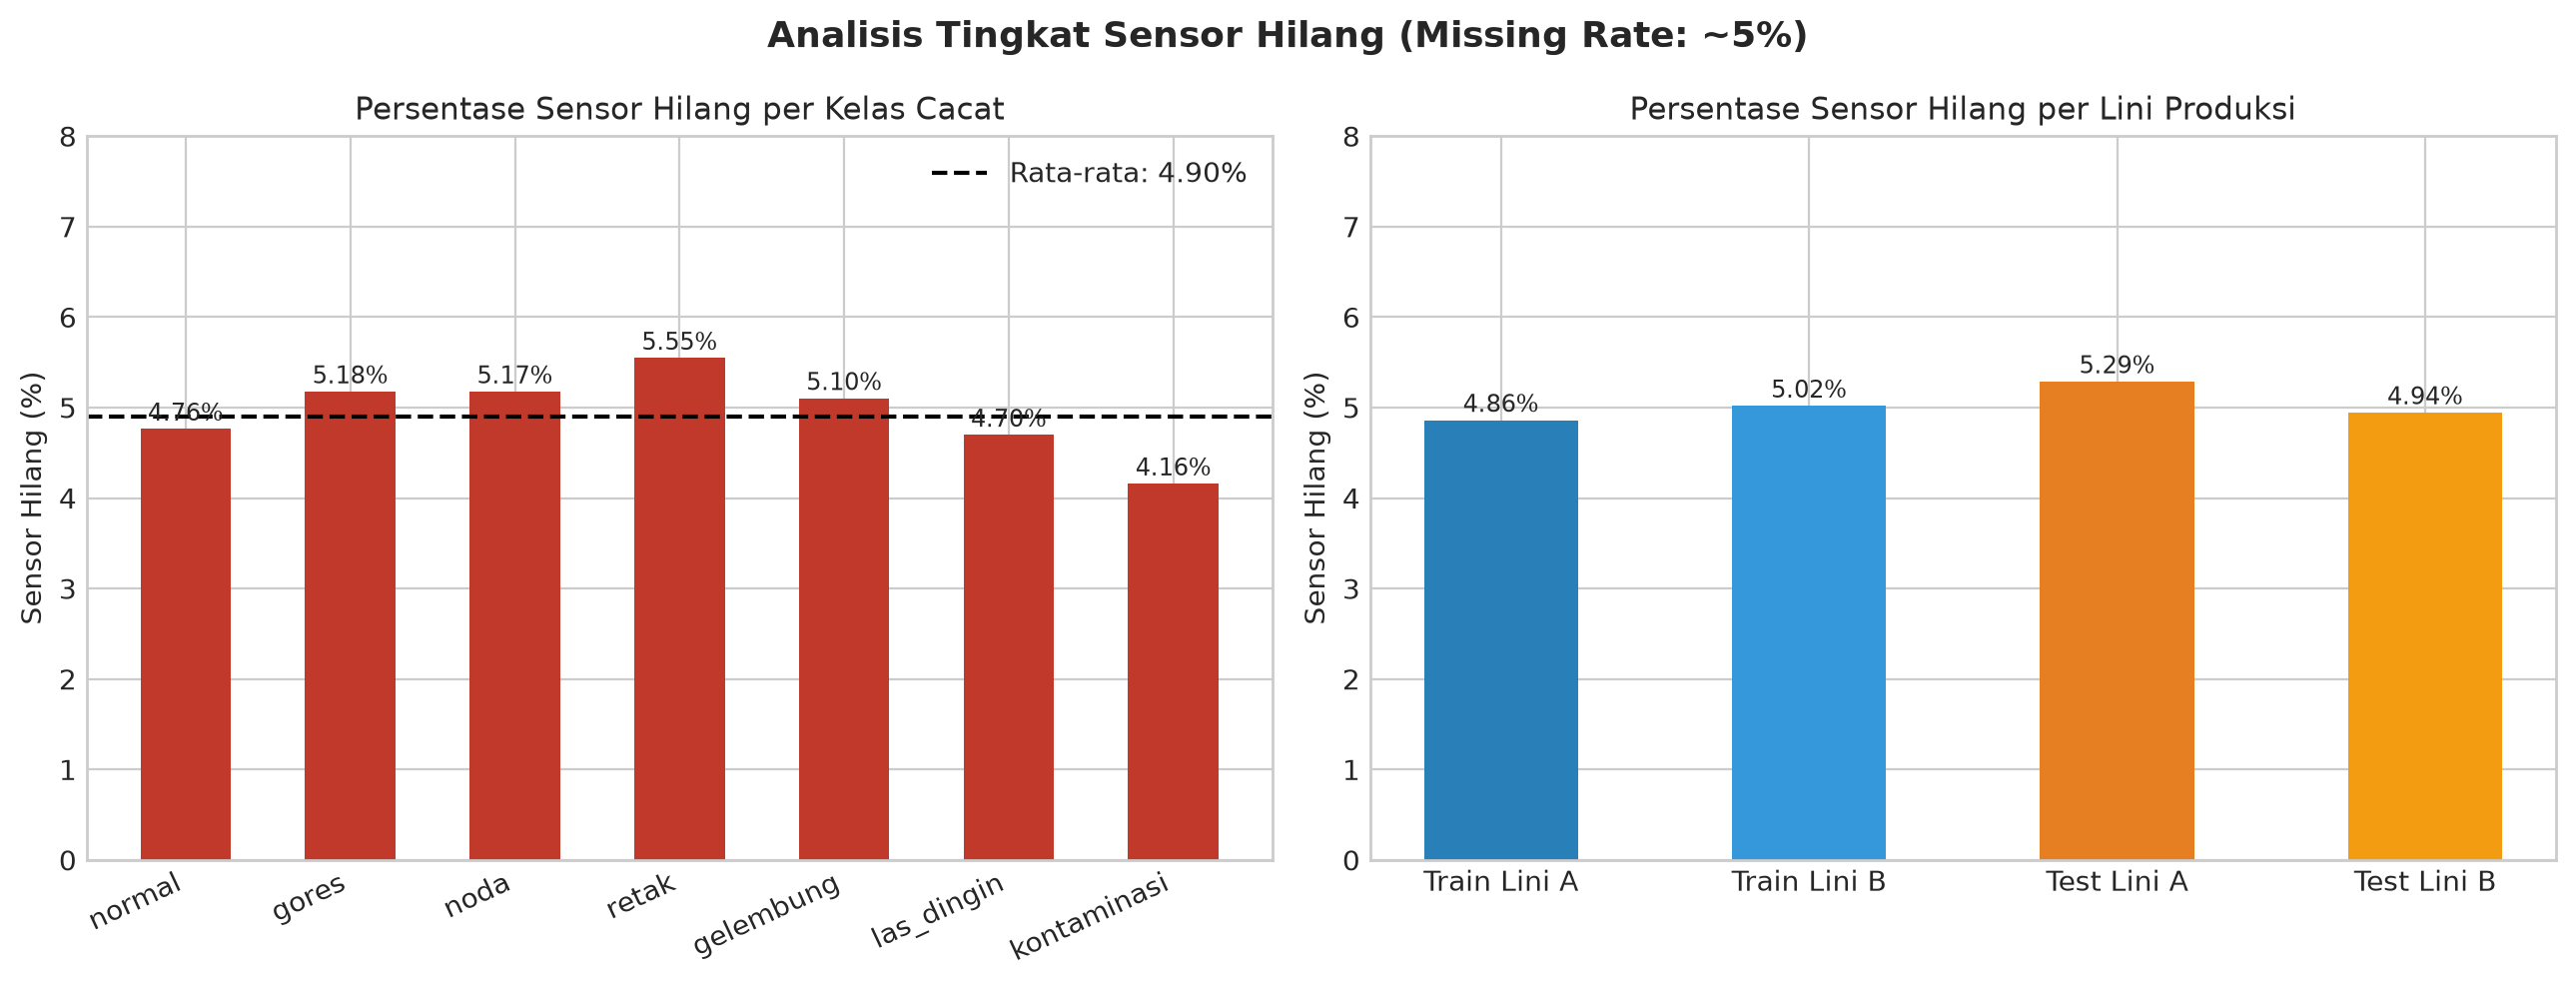

In [5]:
fig_a3 = os.path.join(artifacts_dir, 'fig_a3_missing_sensor_rates.png')
if os.path.exists(fig_a3):
    display(Image(filename=fig_a3))


## 3. Sanity Check Optimasi (Task g)
Verifikasi konvergensi satu mini-batch hingga loss mendekati 0 dan akurasi 100% untuk membuktikan stabilitas gradien.

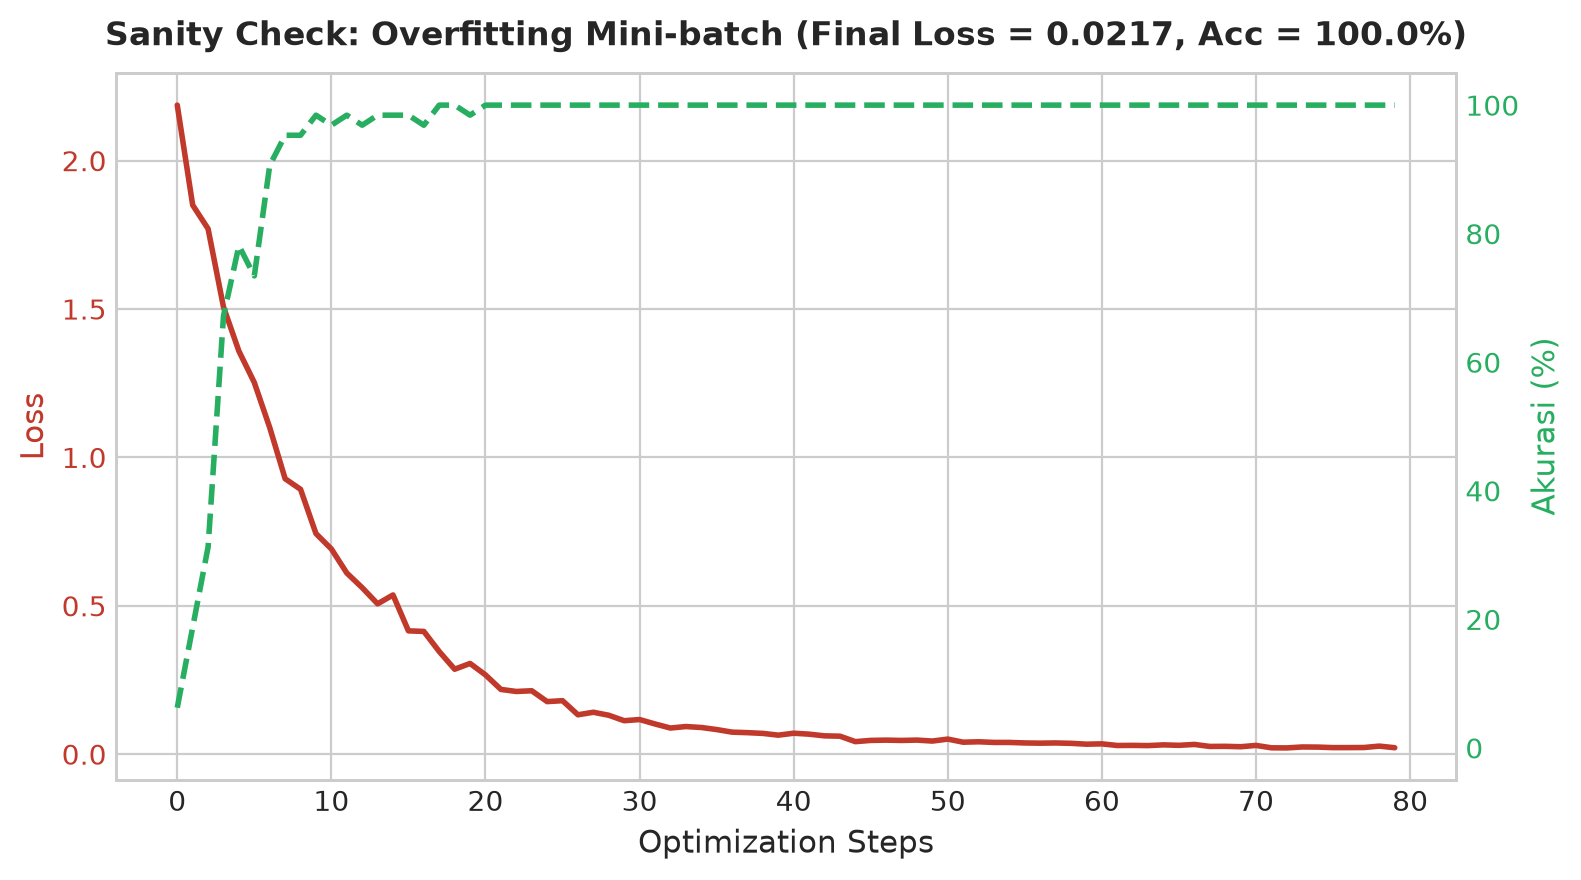

In [6]:
fig_g1 = os.path.join(artifacts_dir, 'fig_g1_sanity_overfit.png')
if os.path.exists(fig_g1):
    display(Image(filename=fig_g1))


## 4. Perbandingan Strategi Fusi Multimodal (Task b)
Membandingkan 3 strategi integrasi modalitas: Early Concat, Late Decision Fusion, dan Cross-Attention.

,Arsitektur,Strategi_Fusi,Jumlah_Parameter,Waktu_Latih_Detik,Macro_F1,Accuracy,F1_normal,F1_gores,F1_noda,F1_retak,F1_gelembung,F1_las_dingin,F1_kontaminasi
0,concat,Early/Concat,1831623,297.4,0.3177,0.5959,0.7405,0.0178,0.0000,0.0000,0.6342,0.8315,0.0
1,late_fusion,Late Decision,1799503,135.0,0.2446,0.5599,0.6929,0.0000,0.0000,0.0000,0.3015,0.7181,0.0
2,cross_attention,Cross-Attention,1963719,70.0,0.3051,0.5896,0.7286,0.0034,0.0228,0.0018,0.5185,0.8608,0.0


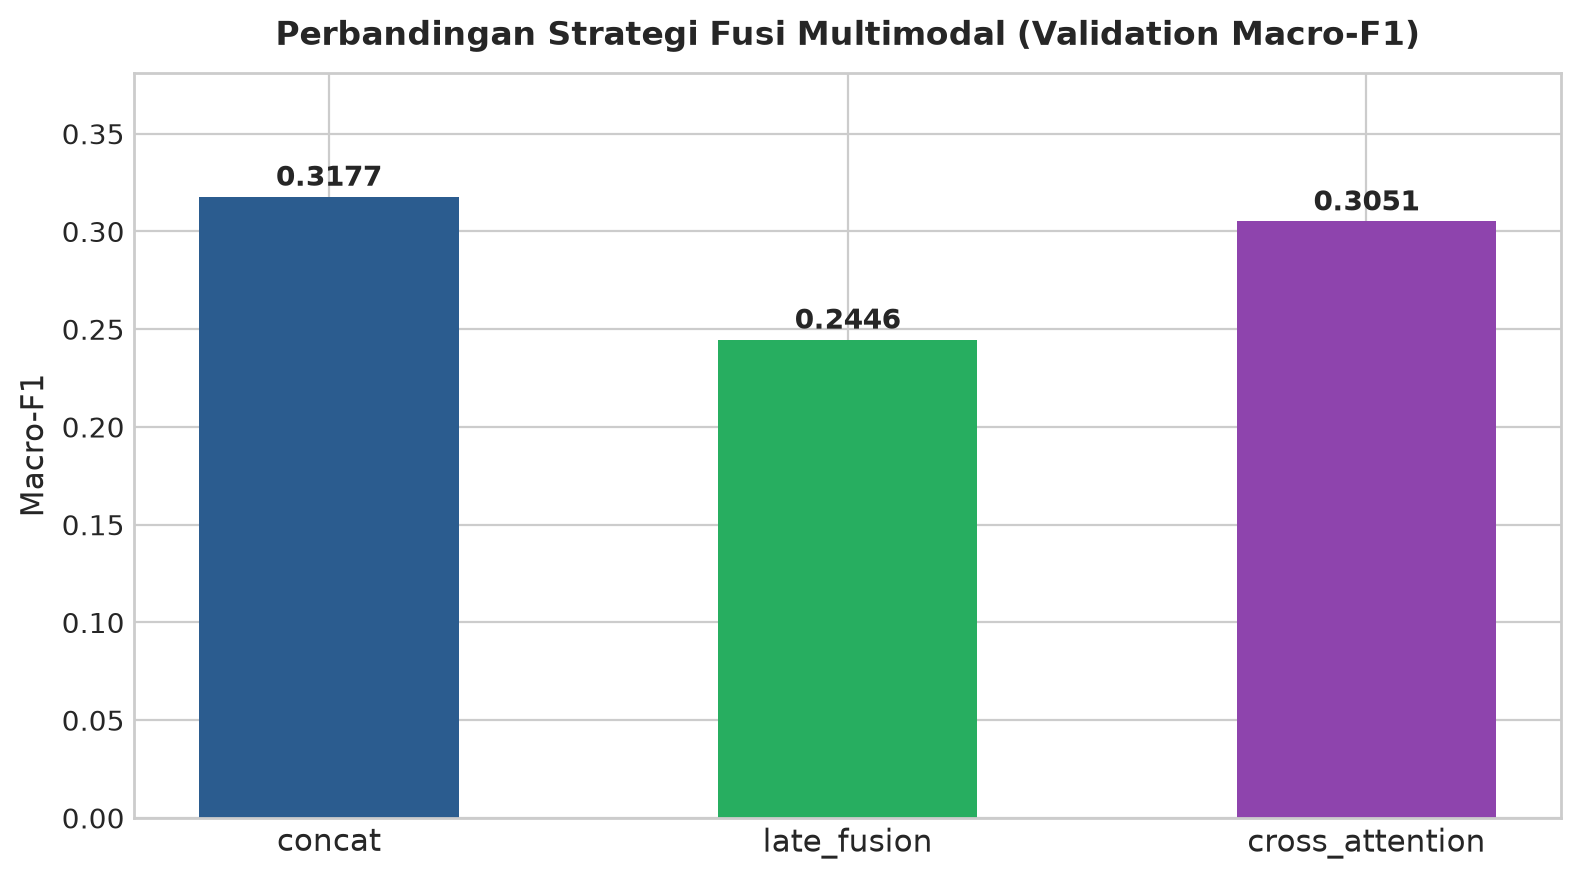

In [7]:
table_b = os.path.join(artifacts_dir, 'table_architecture_comparison.csv')
if os.path.exists(table_b):
    df_b = pd.read_csv(table_b)
    display(df_b)
fig_b = os.path.join(artifacts_dir, 'fig_b1_architecture_comparison.png')
if os.path.exists(fig_b):
    display(Image(filename=fig_b))


## 5. Kontribusi Nilai Tiap Modalitas (Task c: Image-Only vs Sensor-Only vs Multimodal)

,Arsitektur,Strategi_Fusi,Jumlah_Parameter,Waktu_Latih_Detik,Macro_F1,Accuracy,F1_normal,F1_gores,F1_noda,F1_retak,F1_gelembung,F1_las_dingin,F1_kontaminasi,Modalitas
0,concat,Early/Concat,1831623,297.4,0.3177,0.5959,0.7405,0.0178,0.0000,0.0000,0.6342,0.8315,0.0,Multimodal (Image + Sensor)
1,image_only,NaN,1259879,73.4,0.0959,0.4980,0.6653,0.0000,0.0063,0.0000,0.0000,0.0000,0.0,Image-Only
2,signal_only,NaN,539367,53.0,0.4048,0.6343,0.7312,0.0000,0.0000,0.5536,0.6565,0.8926,0.0,Sensor-Only


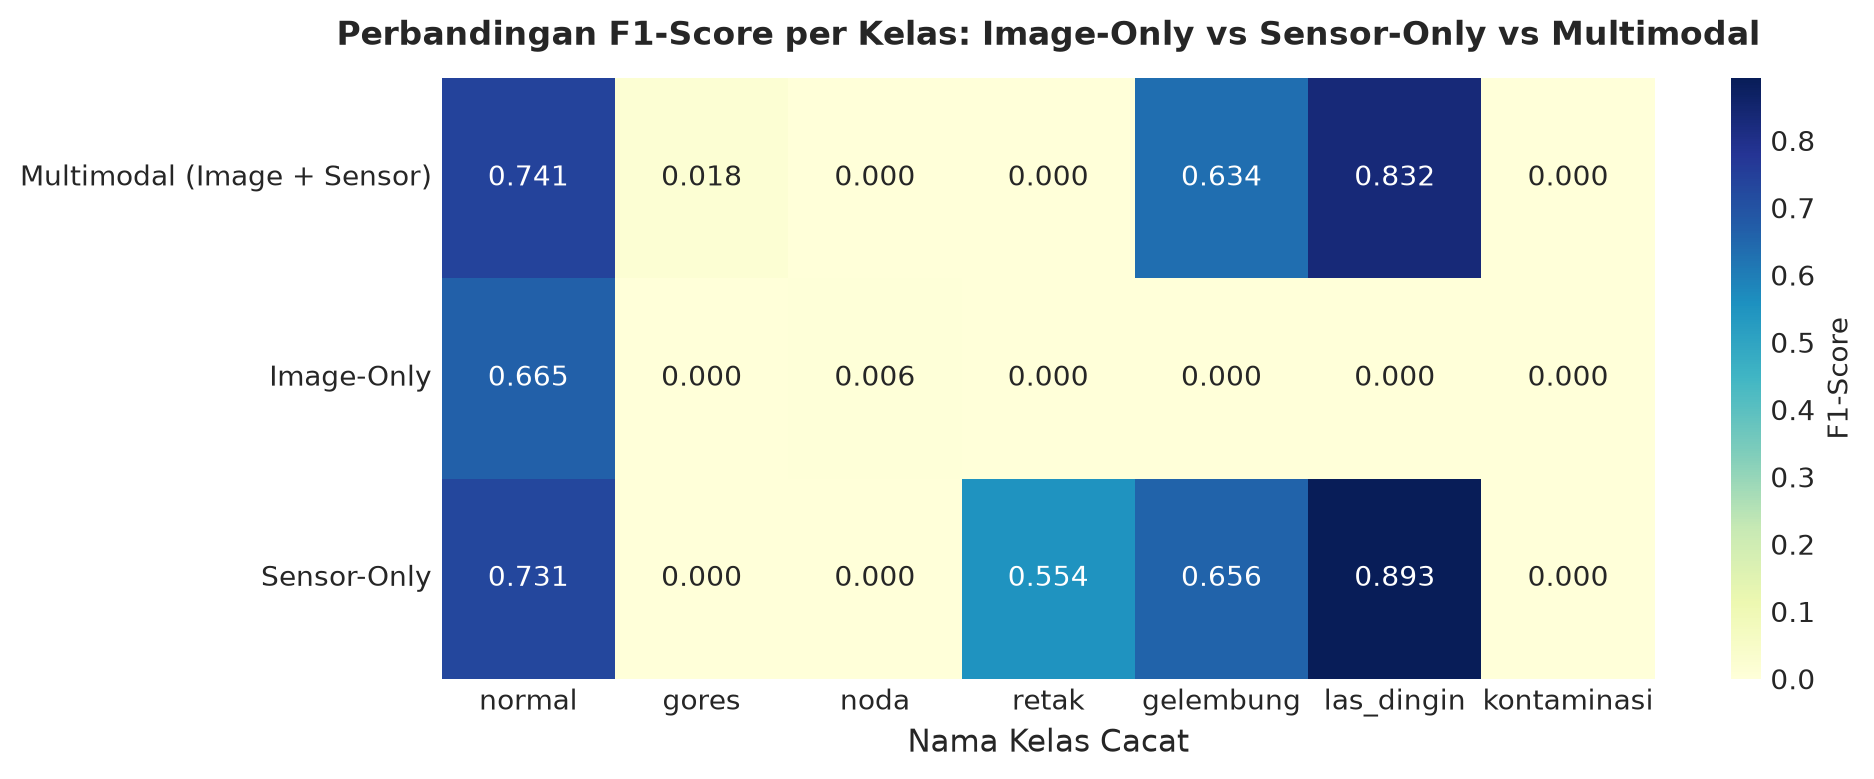

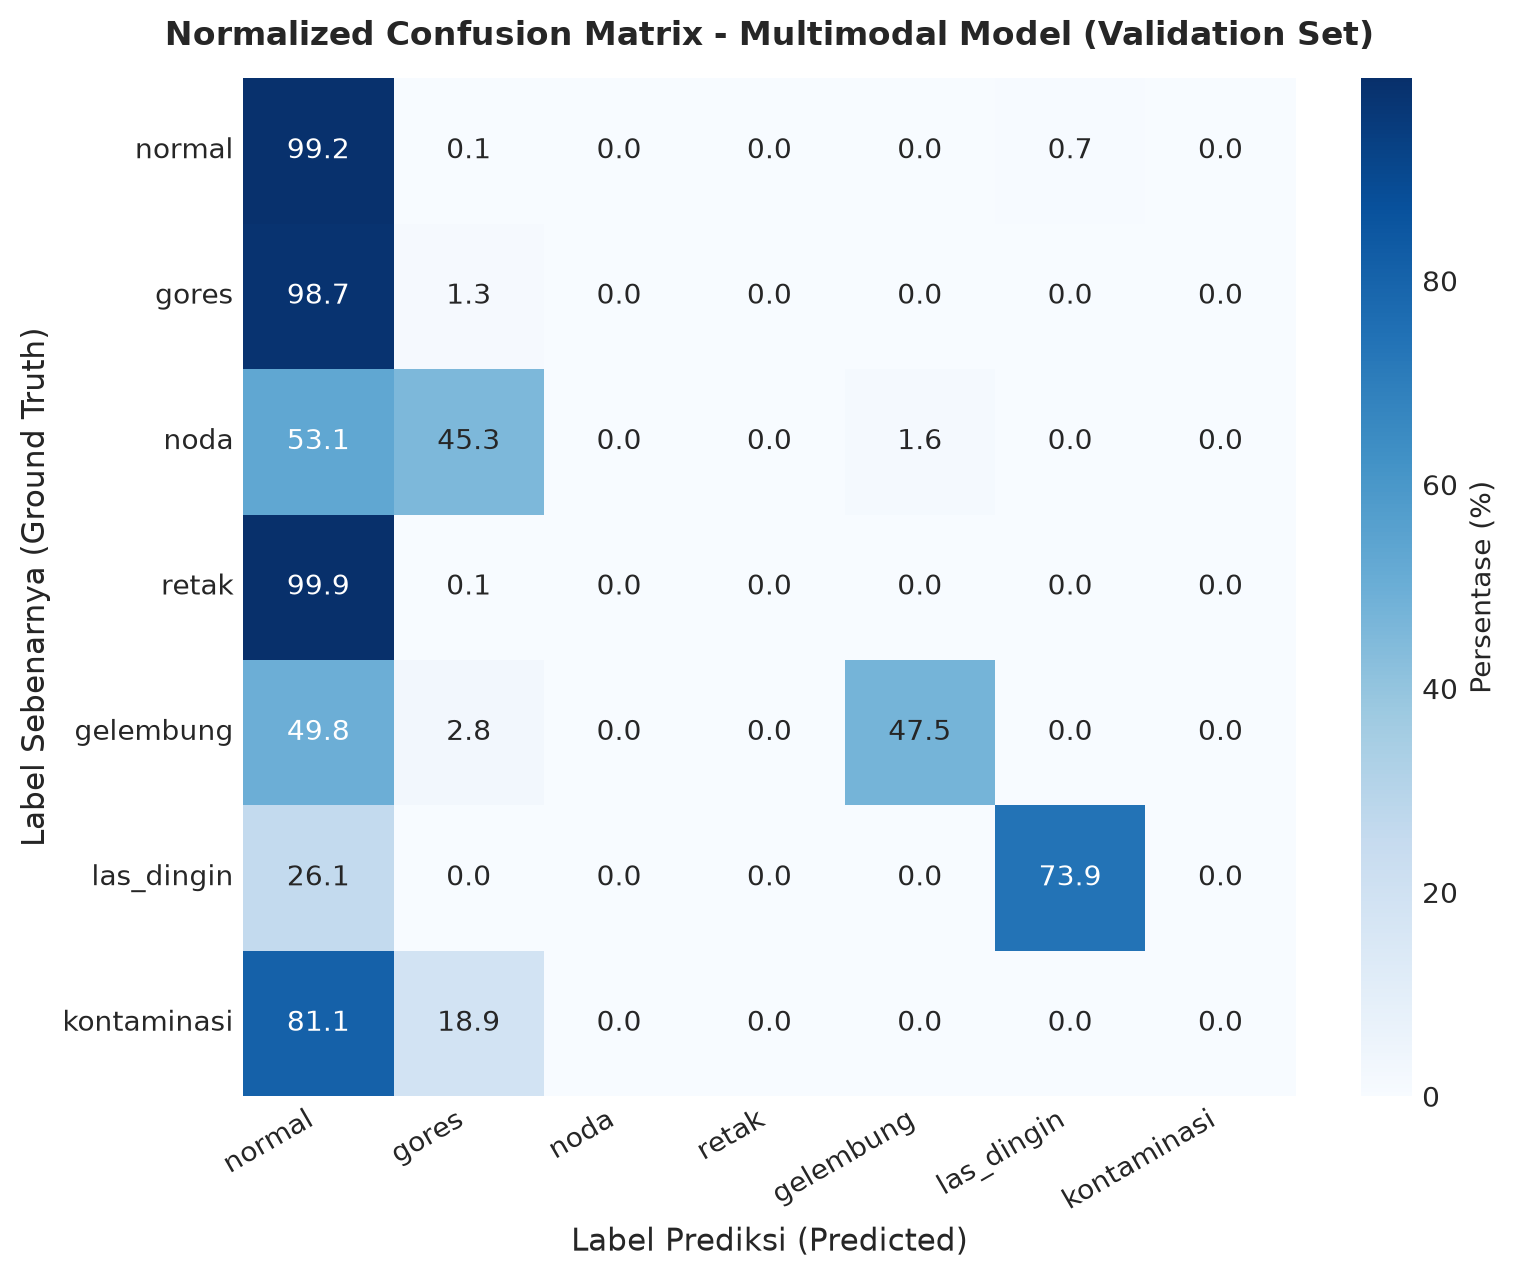

In [8]:
table_c = os.path.join(artifacts_dir, 'table_modality_value.csv')
if os.path.exists(table_c):
    df_c = pd.read_csv(table_c)
    display(df_c)
fig_c1 = os.path.join(artifacts_dir, 'fig_c1_modality_comparison_heatmap.png')
if os.path.exists(fig_c1):
    display(Image(filename=fig_c1))
fig_c2 = os.path.join(artifacts_dir, 'fig_c2_confusion_matrix_multimodal.png')
if os.path.exists(fig_c2):
    display(Image(filename=fig_c2))


## 6. Audit Noisy Labels & Uji Robust Loss (Task d)

,Teknik_Loss,Macro_F1,Accuracy
0,Baseline (Weighted CrossEntropy),0.3177,0.5959
1,Label Smoothing (eps=0.1),0.2957,0.5918
2,Soft Bootstrapping Loss (beta=0.8),0.0255,0.0900


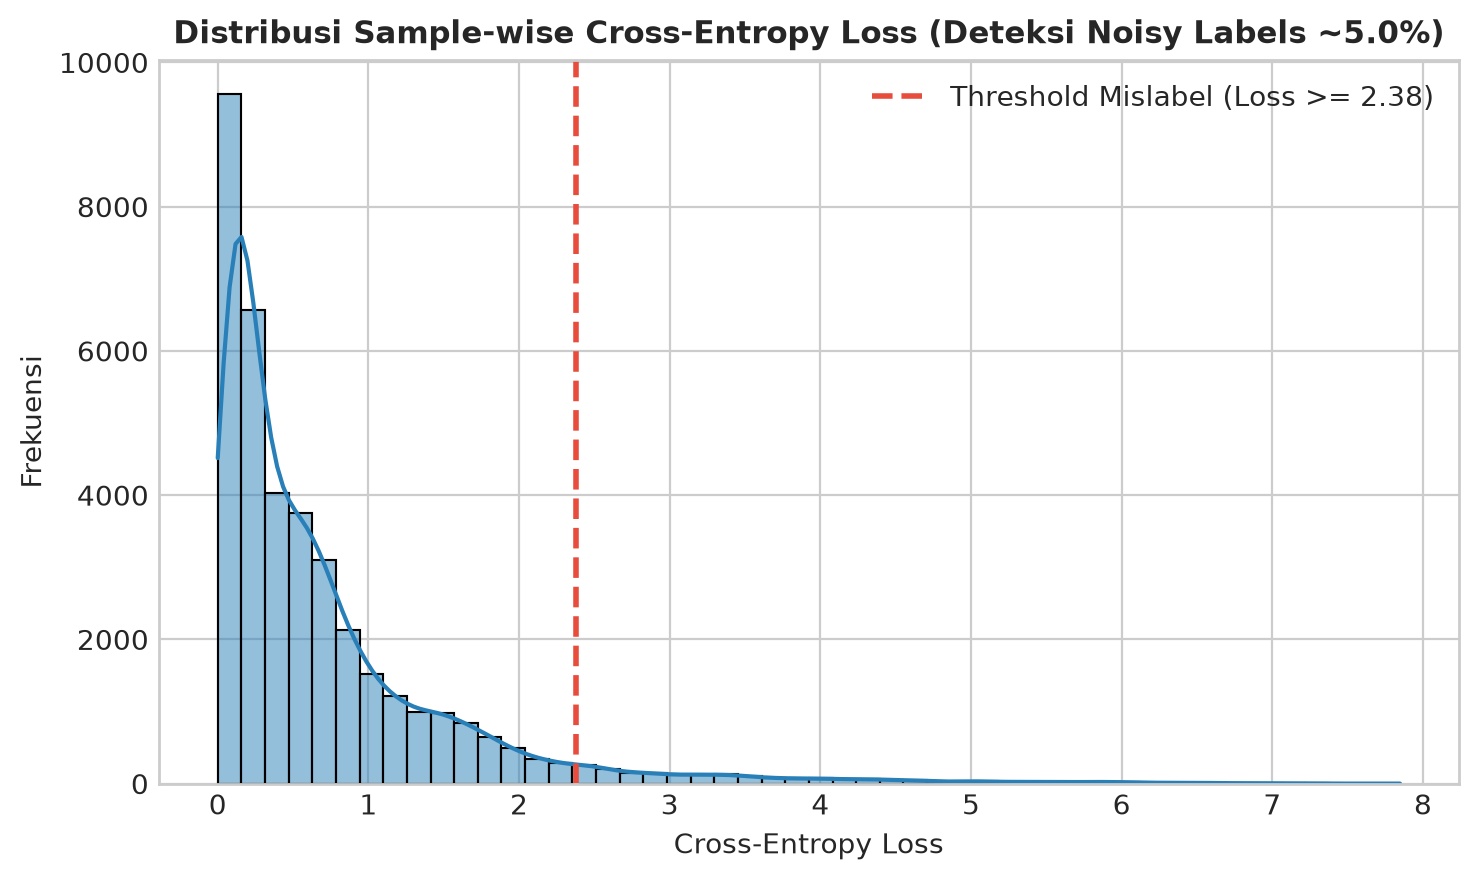

In [9]:
table_d = os.path.join(artifacts_dir, 'table_robust_loss_comparison.csv')
if os.path.exists(table_d):
    display(pd.read_csv(table_d))
fig_d = os.path.join(artifacts_dir, 'fig_d1_loss_distribution_noise.png')
if os.path.exists(fig_d):
    display(Image(filename=fig_d))


## 7. Evaluasi Domain Shift (Task e) & Ketahanan Sensor Hilang (Task f)

--- Performa per Lini Produksi (Domain Shift) ---


,Lini_Produksi,Jumlah_Sampel,Macro_F1,Accuracy
0,Lini A,7193,0.7278,0.7949
1,Lini B,2407,0.5779,0.6851


--- Graceful Degradation Uji Sensor Hilang ---


,Persentase_Sensor_Dimasking,Macro_F1,Accuracy,Penurunan_F1_Relatif
0,0%,0.6945,0.7674,0.0000
1,25%,0.6579,0.7438,0.0366
2,50%,0.6100,0.7193,0.0845
3,100%,0.4694,0.6690,0.2251


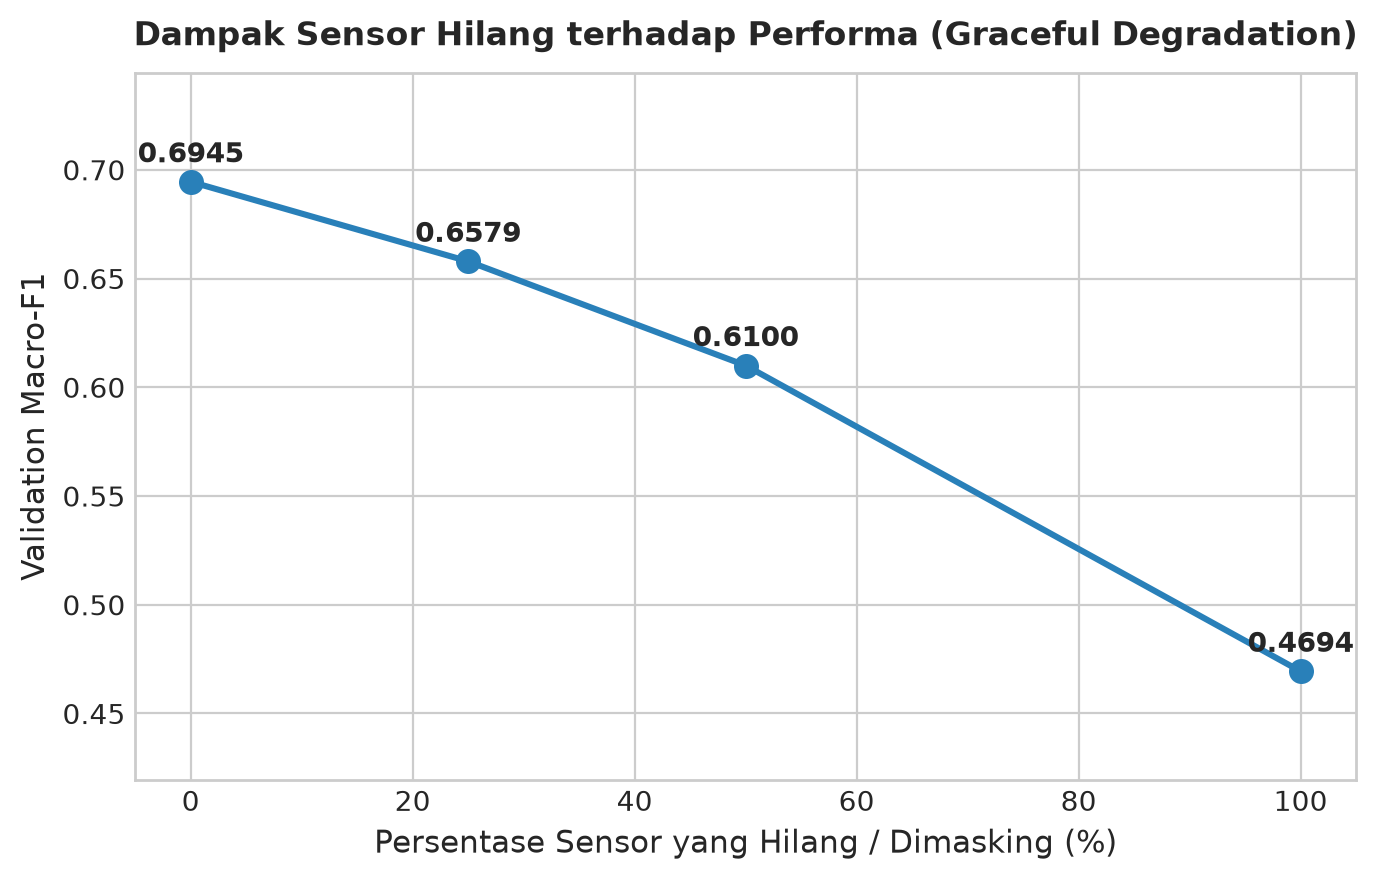

In [10]:
table_e = os.path.join(artifacts_dir, 'table_domain_shift_line_eval.csv')
if os.path.exists(table_e):
    print("--- Performa per Lini Produksi (Domain Shift) ---")
    display(pd.read_csv(table_e))
table_f = os.path.join(artifacts_dir, 'table_missing_modality_eval.csv')
if os.path.exists(table_f):
    print("--- Graceful Degradation Uji Sensor Hilang ---")
    display(pd.read_csv(table_f))
fig_f = os.path.join(artifacts_dir, 'fig_f1_sensor_masking_drop.png')
if os.path.exists(fig_f):
    display(Image(filename=fig_f))


## 8. Model Final 3-Seed Ensemble & Validasi File Submission (Task g)

--- Hasil Validasi 3 Seed Berbeda ---


,Seed,Validation_Macro_F1
0,42,0.3177
1,142,0.3512
2,242,0.2978
3,Mean ± Std,0.3222 ± 0.0221


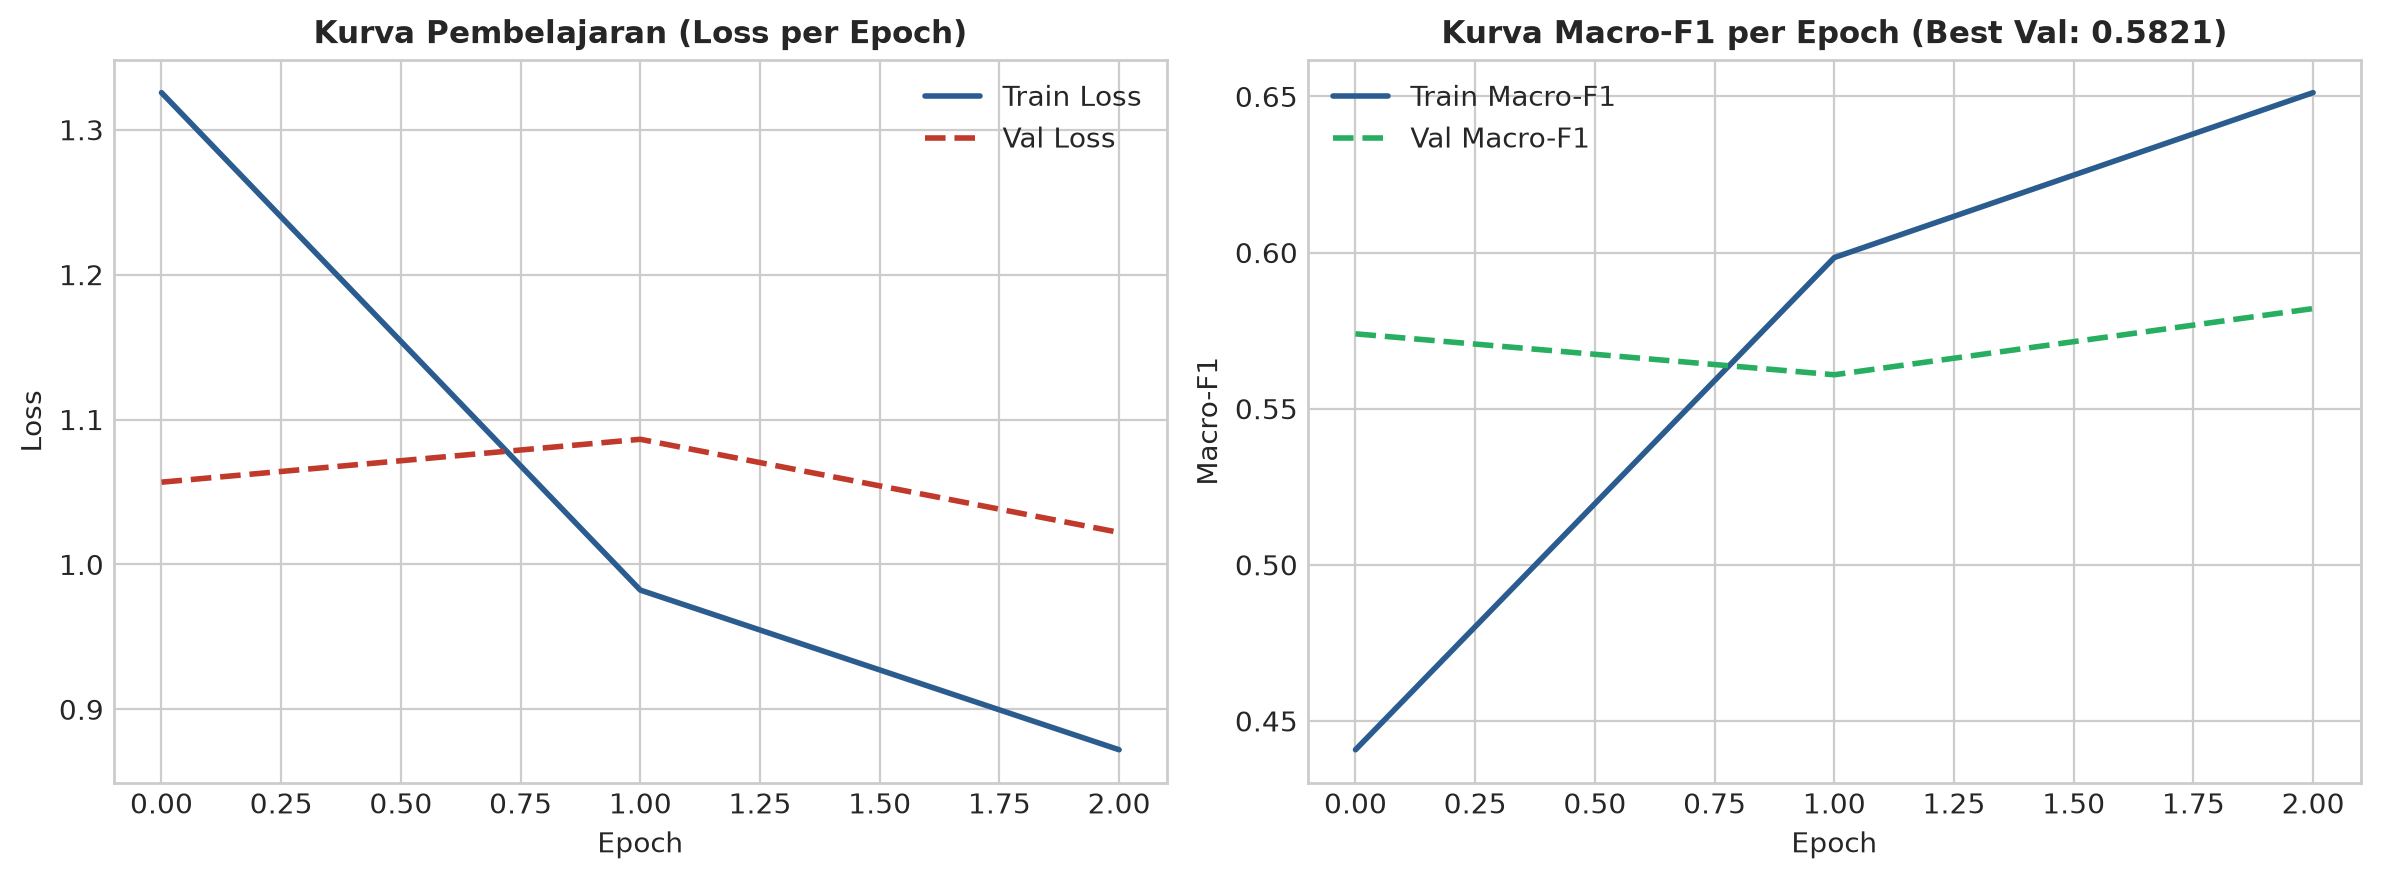


Status File Submission: c:\DL_Classification\prediksi_klasifikasi.csv
Jumlah baris: 16,000 unit
Kolom header: ['id_unit', 'kelas']
Distribusi Prediksi Kelas Data Uji:
kelas
normal         10772
noda            1362
gores           1248
las_dingin      1078
kontaminasi      690
gelembung        580
retak            270
Name: count, dtype: int64


,id_unit,kelas
0,U412019,normal
1,U929275,normal
2,U845264,normal
3,U382231,normal
4,U156089,normal
5,U563952,normal
6,U922240,normal
7,U494185,normal
8,U489550,normal
9,U853085,normal


In [11]:
table_g = os.path.join(artifacts_dir, 'table_seeds_macro_f1.csv')
if os.path.exists(table_g):
    print("--- Hasil Validasi 3 Seed Berbeda ---")
    display(pd.read_csv(table_g))
fig_g2 = os.path.join(artifacts_dir, 'fig_g2_learning_curves.png')
if os.path.exists(fig_g2):
    display(Image(filename=fig_g2))

sub_path = os.path.join(project_root, 'prediksi_klasifikasi.csv')
if os.path.exists(sub_path):
    sub_df = pd.read_csv(sub_path)
    print(f"\nStatus File Submission: {sub_path}")
    print(f"Jumlah baris: {len(sub_df):,} unit")
    print("Kolom header:", list(sub_df.columns))
    print("Distribusi Prediksi Kelas Data Uji:")
    print(sub_df['kelas'].value_counts())
    display(sub_df.head(10))
else:
    print("File prediksi_klasifikasi.csv sedang digenerasi oleh background training...")
